# Residual Plot
- residuals are used to evaluate regression problems
- x-axis - predicted values
- y-axis - residuals
- ideal: random scatter
- curved/u-shaped - nonlinearity
- funnel - heteroscedasticity
- clustered points and outliers

Training: 10661 rows | 70 unique players
Validation: 2169 rows | 15 unique players
Testing: 2170 rows | 15 unique players


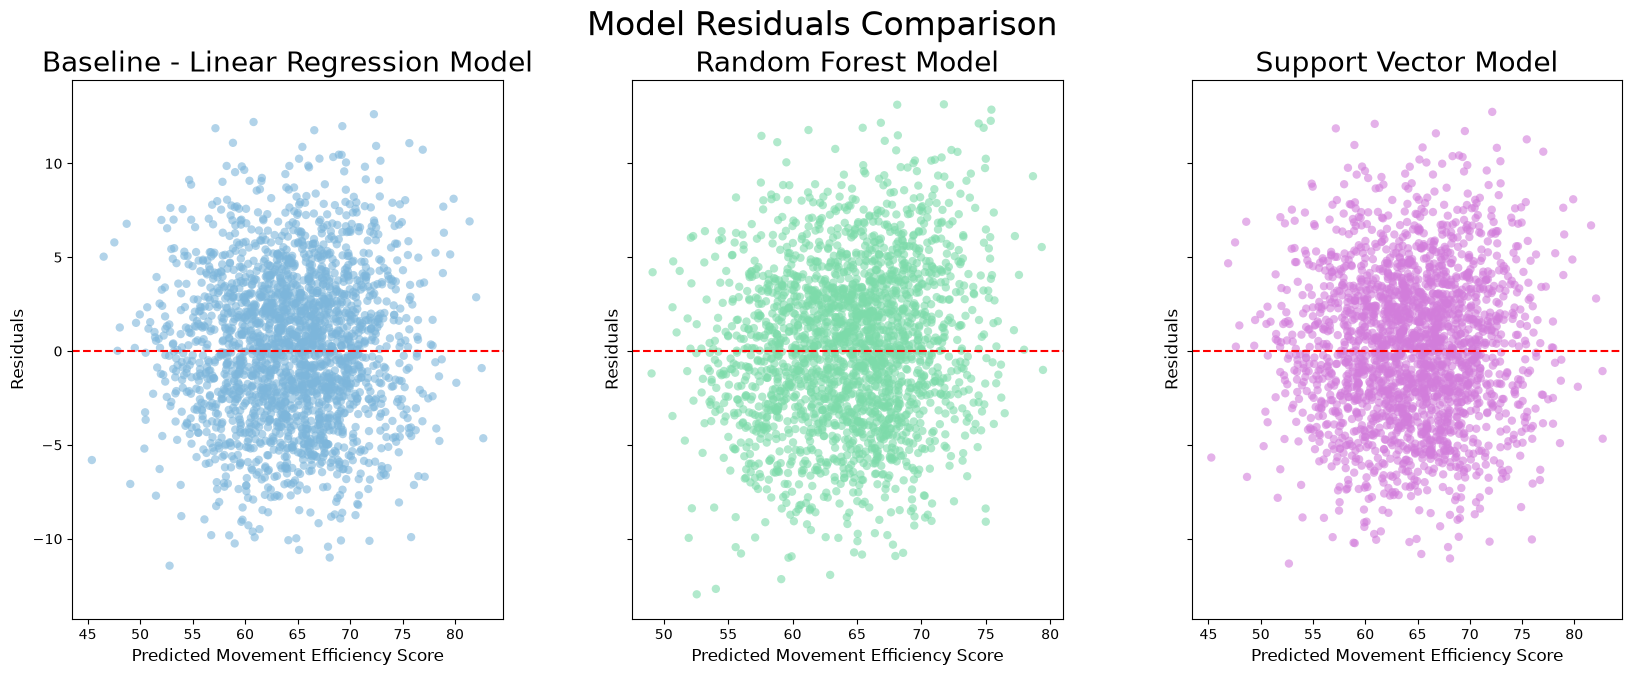

In [41]:
import joblib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
#need to access the testing fold so import from the data_splitter Python script to load and split the data
import sys
import os
sys.path.append(os.path.abspath(os.path.join('..'))) #used to move to the parent folder
from src.data_splitter import load_data, split

#load dataset and variables
df, X, y = load_data()

#split data by groups
X_train, X_val, X_test, y_train, y_val, y_test = split(df, X, y)

#load the models using joblib
baseline = joblib.load('baseline.joblib')
random_forest = joblib.load('random_forest.joblib')
support_vector = joblib.load('support_vector.joblib')

#placing the plots besides each other
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 7), sharey=True, gridspec_kw={'wspace': 0.3})

#baseline plot
baseline_y_pred = baseline.predict(X_test)
baseline_res = y_test - baseline_y_pred #calculate residuals (acual value - predicted value)

ax1.set_title('Baseline - Linear Regression Model', fontsize=20)
ax1.scatter(baseline_y_pred, baseline_res, alpha=.6, c='#7db6db', edgecolors='none')
ax1.axhline(y=0, color='r', linestyle='--')
ax1.set_xlabel('Predicted Movement Efficiency Score', fontsize=12)
ax1.set_ylabel('Residuals', fontsize=12)

#random forest plot
rf_y_pred = random_forest.predict(X_test)
rf_res = y_test - rf_y_pred #calculate residuals (acual value - predicted value)

ax2.set_title('Random Forest Model', fontsize=20)
ax2.scatter(rf_y_pred, rf_res, alpha=.6, c='#7ddbaa', edgecolors='none')
ax2.axhline(y=0, color='r', linestyle='--')
ax2.set_xlabel('Predicted Movement Efficiency Score', fontsize=12)
ax2.set_ylabel('Residuals', fontsize=12)

#support vector plot
sv_y_pred = support_vector.predict(X_test)
sv_res = y_test - sv_y_pred #calculate residuals (acual value - predicted value)

ax3.set_title('Support Vector Model', fontsize=20)
ax3.scatter(sv_y_pred, sv_res, alpha=.6, c='#d27ddb', edgecolors='none')
ax3.axhline(y=0, color='r', linestyle='--')
ax3.set_xlabel('Predicted Movement Efficiency Score', fontsize=12)
ax3.set_ylabel('Residuals', fontsize=12)

plt.suptitle('Model Residuals Comparison', fontsize=24)
plt.show()

# Residual Analysis
## Baseline - Linear Regression
- linearity - centered evenly around y=0 line
- heteroscedasticity (constant variance) - no cone/funnel shape
- independence - may be violated since players are repeated and the errors may not be independent
- few outliers but won't dramatically affect model